# 05 · Reinforcement Learning with Verifiable Rewards: GRPO and What RL Actually Adds

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Pretraining | Next-token prediction on raw text | Knowledge: the model *can* add | Doesn't follow instructions |
| 02 | SFT + LoRA | Imitate demonstrations | Follows the chat format | Copies demonstrators' mistakes; forgets |
| 03 | Reward model + PPO | Learn a reward from preferences, optimise it | Can go beyond imitation | Reward hacking; four models; fragile |
| 04 | DPO family | Optimise preferences directly, no RL loop | Simple and stable | Offline: only re-weights existing behaviour |
| **05** | **GRPO / RLVR** | **Online RL against a verifier** | **Verifiable gains, no value network** | **Sharpens, rarely expands; needs a capable start** |
| 06 | Diffusion | Learn to denoise | Stable, high-quality generation | Matches data, not *goals*; slow sampling |
| 07 | Diffusion post-training | Fine-tune and reward-align a denoiser | Steer generation to a goal | Reward hacking again; still slow |
| 08 | Distillation | Few-step students | 10-100x faster sampling | Small denoisers don't scale |
| 09 | Diffusion transformers | Tokens + adaLN + flow matching | Scalable, flexible conditioning | Needs post-training too |
| 10 | Capstone | GRPO and DPO on a DiT; diffusion LMs | Unifies both threads | → the research frontier |

Notebooks 03 and 04 optimised **learned** preferences, and both ran into the same problem: a learned
reward can be exploited, and an offline dataset can only re-weight the behaviour it already contains. For
many tasks, though, correctness can be **checked**: a maths answer, a unit test, a proof checker. Training on
such checks is *reinforcement learning with verifiable rewards* (RLVR), named in Tülu 3 ([Lambert et al., 2024](https://arxiv.org/abs/2411.15124))
and behind the reasoning models of 2024-25, most visibly DeepSeek-R1 ([DeepSeek-AI et al., 2025](https://arxiv.org/abs/2501.12948)).

The algorithm most associated with RLVR is **GRPO** ([Shao et al., 2024](https://arxiv.org/abs/2402.03300)). It is PPO without the value network:
sample a *group* of answers to the same prompt and use each answer's reward relative to the group as its
advantage. We use a harder task than before, **3-digit addition**, which the SFT model was never shown in chat format.

## Learning objectives

1. Derive the policy-gradient estimator and explain why baselines (RLOO, group normalisation) reduce its variance.
2. Show that RL needs a starting point with non-zero success, and fix it with a small **cold-start** SFT, as R1 does.
3. Compare REINFORCE, RLOO, GRPO and Dr. GRPO ([Liu et al., 2025](https://arxiv.org/abs/2503.20783)), plus rejection-sampling fine-tuning (STaR, [Zelikman et al., 2022](https://arxiv.org/abs/2203.14465)), on the same budget.
4. Use **pass@k** ([Chen et al., 2021](https://arxiv.org/abs/2107.03374)) to test whether RL teaches new abilities or sharpens existing ones ([Yue et al., 2025](https://arxiv.org/abs/2504.13837)).

**Runtime:** about 8 minutes on a laptop CPU.

In [1]:
import sys, time, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, ".")
from ptlib import tasks, lm, align, metrics, set_seed
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
sft = align.get_sft()
EVAL3 = tasks.TEST_3D[:200]          # held-out 3-digit problems

## 1. Policy gradients and baselines

We want to maximise $J(\theta) = \mathbb{E}_{x}\,\mathbb{E}_{y \sim \pi_\theta(\cdot\mid x)}[R(x, y)]$, where $R$ is the verifier
(1 if correct, else 0). The log-derivative trick ([Williams, 1992](https://doi.org/10.1007/BF00992696)) gives an estimator that only needs samples:
$$\nabla_\theta J = \mathbb{E}\big[(R(x,y) - b(x))\,\nabla_\theta \log\pi_\theta(y\mid x)\big],$$
which is valid for any **baseline** $b(x)$ that does not depend on $y$. A good baseline does not change the
expected gradient, but it can greatly reduce its variance. With $G$ samples per prompt:

| Method | Advantage $A_i$ for sample $i$ of a group | Notes |
|---|---|---|
| REINFORCE | $R_i$ | no baseline: every correct answer is pushed up, nothing is pushed down |
| RLOO ([Ahmadian et al., 2024](https://arxiv.org/abs/2402.14740)) | $R_i - \frac{1}{G-1}\sum_{j\neq i} R_j$ | leave-one-out mean: unbiased |
| GRPO ([Shao et al., 2024](https://arxiv.org/abs/2402.03300)) | $(R_i - \bar R)/\mathrm{std}(R)$ | group-normalised; plus PPO's clipped ratio and a KL penalty |
| Dr. GRPO ([Liu et al., 2025](https://arxiv.org/abs/2503.20783)) | $R_i - \bar R$ | drops the std division, which over-weights nearly-solved and nearly-hopeless prompts |

If every answer in a group gets the same reward, all four advantages are zero (or constant), and that group
teaches nothing. We log the fraction of such groups.

In [2]:
print(inspect.getsource(align.group_advantages))
r = torch.tensor([1., 0., 0., 1., 1., 1., 1., 1.])            # two prompts, G = 4
for k in ["none", "rloo", "grpo", "dr_grpo"]:
    print(f"{k:8s}", align.group_advantages(r, 4, k).numpy().round(2))
src = inspect.getsource(align.group_rl)
print(src[src.index("        P = [p for p"):src.index("        g = r.view")])

def group_advantages(r, G, kind="grpo"):
    """r: (n_prompts * G,) rewards, grouped consecutively per prompt.

    none      : REINFORCE, advantage = reward                          (Williams, 1992)
    rloo      : leave-one-out baseline, r_i - mean_{j != i} r_j          (Ahmadian et al., 2024)
    grpo      : (r_i - mean) / std within the group                     (Shao et al., 2024)
    dr_grpo   : r_i - mean, without the std division                   (Liu et al., 2025)
    """
    g = r.view(-1, G)
    if kind == "none":
        a = g
    elif kind == "rloo":
        a = g - (g.sum(1, keepdim=True) - g) / (G - 1)
    elif kind == "grpo":
        a = (g - g.mean(1, keepdim=True)) / (g.std(1, keepdim=True) + 1e-4)
    elif kind == "dr_grpo":
        a = g - g.mean(1, keepdim=True)
    else:
        raise ValueError(kind)
    return a.reshape(-1)

none     [1. 0. 0. 1. 1. 1. 1. 1.]
rloo     [ 0.67 -0.67 -0.67  0.67  0.    0.    0.    0.  ]
grpo     [ 0.87 -0.87 -0.87  0.87  0.    0. 

## 2. RL needs something to reinforce

How does the SFT model do on 3-digit problems in the chat format? Notebook 01's base model got about 41% of 3-digit sums right
in the `a+b=` format, so the knowledge exists. Pass@k is the probability that at least one of $k$ samples is correct
(unbiased estimator from $n=32$ samples per problem, [Chen et al., 2021](https://arxiv.org/abs/2107.03374)).

In [3]:
print("SFT on 3-digit chat:", {k: round(v, 3) for k, v in align.evaluate(sft, EVAL3, digits=3).items()})
pk = {"SFT": align.pass_at_k(sft, EVAL3[:100])}
print("pass@k:", {k: round(v, 3) for k, v in pk["SFT"].items()})
rng = np.random.default_rng(0)
for a, b in EVAL3[:4]:
    print(f"  {a}+{b}={a + b}", repr(lm.generate(sft, [tasks.make_prompt(a, b, rng=rng)], greedy=True)[0]))

SFT on 3-digit chat: {'greedy_acc': 0.005, 'sampled_acc': 0.005, 'well_formed': 0.98, 'sentence_style': 0.59, 'mean_len': 13.77}
pass@k: {1: 0.006, 2: 0.012, 4: 0.021, 8: 0.034, 16: 0.05, 32: 0.07}
  850+567=1417 ' the answer is 166.\n'
  114+314=428 ' the answer is 45.\n'
  670+381=1051 ' the answer is 98.\n'
  829+270=1099 ' the answer is 101.\n'


SFT on 2-digit demonstrations taught the model that **answers have two or three digits**, and it now truncates
3-digit sums. Pass@32 is only a few percent. What happens if we run GRPO from here anyway?

In [4]:
policy, ref = align.get_sft(verbose=False), align.get_sft(verbose=False); ref.requires_grad_(False)
h_sft = align.group_rl(policy, ref, steps=40, adv="grpo", log_every=10)
print("after 40 GRPO iterations:", {k: round(v, 3) for k, v in align.evaluate(policy, EVAL3, digits=3).items()})

iter   10  train reward 0.000  groups w/o signal 1.00  KL 0.132  (4s)
iter   20  train reward 0.094  groups w/o signal 0.75  KL 0.761  (8s)
iter   30  train reward 0.047  groups w/o signal 0.94  KL 1.587  (13s)
iter   40  train reward 0.062  groups w/o signal 0.75  KL 2.885  (17s)
after 40 GRPO iterations: {'greedy_acc': 0.165, 'sampled_acc': 0.1, 'well_formed': 0.97, 'sentence_style': 0.635, 'mean_len': 15.01}


Most groups are all-wrong, so most advantages are zero (look at "groups w/o signal"). The rare lucky groups give a
weak, noisy signal: after 40 iterations the model creeps from 0.5% to about 10%, while its KL from the start grows
quickly. This is the practical meaning of "RL can only reinforce what the policy already does sometimes": learning
is slow and expensive when successes are rare. DeepSeek-R1-Zero worked
because its base model was already strong. R1 itself first ran a small **cold-start SFT** on a few thousand
curated long-reasoning examples, then RL ([DeepSeek-AI et al., 2025](https://arxiv.org/abs/2501.12948)).

## 3. Cold start: a little SFT on the new task

We fine-tune the SFT model on 300 clean 3-digit demonstrations, plus 300 clean 2-digit ones so it keeps the
old task.

In [5]:
cold_data = tasks.demonstrations(300, digits=3, p_sloppy=0.0, seed=7) + tasks.demonstrations(300, digits=2, p_sloppy=0.0, seed=8)
cold = align.get_sft(verbose=False)
align.sft(cold, cold_data, epochs=2, lr=3e-4, log=False)
lm.save(cold, "coldstart_lm")
res = {"SFT": {**align.evaluate(sft, EVAL3, digits=3), "acc_2d_sampled": align.evaluate(sft)["sampled_acc"], "kl_to_start": np.nan},
       "cold start (SFT + 600 demos)": {**align.evaluate(cold, EVAL3, digits=3), "acc_2d_sampled": align.evaluate(cold)["sampled_acc"], "kl_to_start": 0.0}}
pk["cold start"] = align.pass_at_k(cold, EVAL3[:100])
display(pd.DataFrame(res).T.round(3))
print("pass@k cold start:", {k: round(v, 3) for k, v in pk["cold start"].items()})

,greedy_acc,sampled_acc,well_formed,sentence_style,mean_len,acc_2d_sampled,kl_to_start
SFT,0.005,0.005,0.980,0.590,13.77,0.775,NaN
cold start (SFT + 600 demos),0.725,0.540,0.985,0.785,17.53,0.825,0.0


pass@k cold start: {1: 0.534, 2: 0.725, 4: 0.851, 8: 0.921, 16: 0.964, 32: 0.99}


## 4. Four policy-gradient estimators on the same budget

Each run: 100 iterations × 16 prompts × $G = 8$ samples, verifier reward, clipped ratio with 2 inner steps,
KL coefficient 0.04 (the "k3" estimator used by GRPO). All four start from the cold-start model.

In [6]:
logs, pols = {}, {}
for name, adv in [("REINFORCE", "none"), ("RLOO", "rloo"), ("GRPO", "grpo"), ("Dr. GRPO", "dr_grpo")]:
    print("==", name)
    policy, ref = lm.load("coldstart_lm"), lm.load("coldstart_lm"); ref.requires_grad_(False)
    t0 = time.time()
    logs[name] = align.group_rl(policy, ref, steps=100, adv=adv, log_every=50)
    pols[name] = policy
    res[name] = {**align.evaluate(policy, EVAL3, digits=3), "acc_2d_sampled": align.evaluate(policy)["sampled_acc"],
                 "kl_to_start": align.kl_to_ref(policy, ref, EVAL3, digits=3), "seconds": time.time() - t0}
display(pd.DataFrame(res).T.round(3))

== REINFORCE
iter   50  train reward 0.695  groups w/o signal 0.25  KL 1.979  (21s)
iter  100  train reward 0.852  groups w/o signal 0.31  KL 2.265  (42s)
== RLOO
iter   50  train reward 0.781  groups w/o signal 0.12  KL 0.241  (23s)
iter  100  train reward 0.703  groups w/o signal 0.31  KL 0.132  (45s)
== GRPO
iter   50  train reward 0.812  groups w/o signal 0.25  KL 0.198  (23s)
iter  100  train reward 0.789  groups w/o signal 0.31  KL 0.332  (45s)
== Dr. GRPO
iter   50  train reward 0.789  groups w/o signal 0.12  KL 0.237  (23s)
iter  100  train reward 0.758  groups w/o signal 0.31  KL 0.344  (45s)


,greedy_acc,sampled_acc,well_formed,sentence_style,mean_len,acc_2d_sampled,kl_to_start,seconds
SFT,0.005,0.005,0.980,0.590,13.770,0.775,NaN,NaN
cold start (SFT + 600 demos),0.725,0.540,0.985,0.785,17.530,0.825,0.000,NaN
REINFORCE,0.855,0.730,0.990,0.010,5.740,0.872,2.599,43.044
RLOO,0.855,0.710,0.975,0.925,19.785,0.865,0.385,46.723
GRPO,0.850,0.695,0.975,0.955,20.235,0.845,0.511,46.658
Dr. GRPO,0.850,0.730,0.980,0.930,19.765,0.848,0.379,46.670


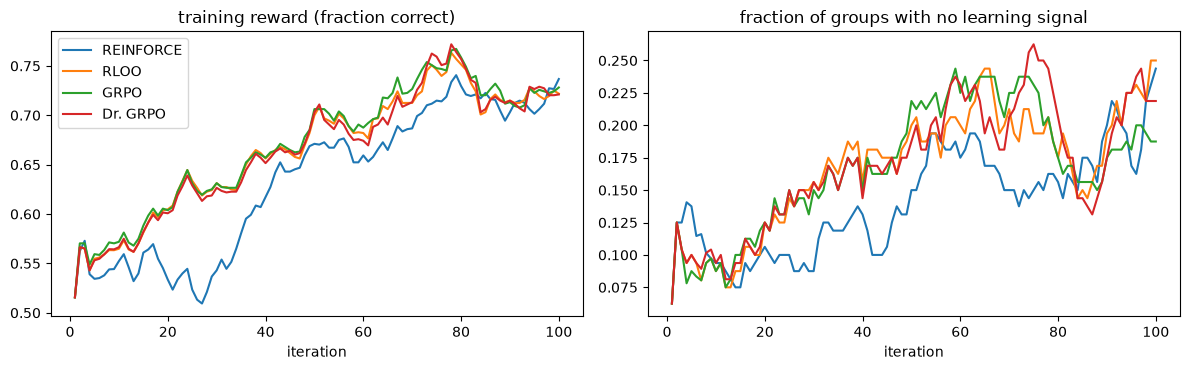

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, h in logs.items():
    axes[0].plot(h.step, h.reward.rolling(10, min_periods=1).mean(), label=name)
    axes[1].plot(h.step, h.frac_groups_no_signal.rolling(10, min_periods=1).mean(), label=name)
axes[0].set_title("training reward (fraction correct)"); axes[0].set_xlabel("iteration"); axes[0].legend()
axes[1].set_title("fraction of groups with no learning signal"); axes[1].set_xlabel("iteration")
fig.tight_layout(); plt.show()

**Reading the comparison.** Use the printed table; one seed per method, so treat small gaps as noise.

* Every estimator improves held-out 3-digit accuracy over the cold start by a similar amount, with no reward model and no value network.
* **REINFORCE without a baseline** matches the others on accuracy but takes a very different path. Its KL from the start is several times larger, and it abandons full sentences almost entirely (`sentence_style` near 0, `mean_len` drops). With only non-negative advantages every sampled correct answer is pushed up, and because our loss averages over each answer's tokens, short answers receive a larger per-token push. This length bias from per-sequence normalisation is exactly what [Liu et al., 2025](https://arxiv.org/abs/2503.20783) point out in GRPO. Baselines that also push *down* wrong answers keep the policy much closer to where it started.
* As the policy improves, more groups become all-correct and stop contributing (right panel). DAPO ([Yu et al., 2025](https://arxiv.org/abs/2503.14476)) addresses this with "dynamic sampling", resampling until each group has mixed outcomes.
* The KL to the starting model stays small. RLVR improves the task by moving the policy only a little.

## 5. Rejection sampling: the supervised alternative

**STaR** ([Zelikman et al., 2022](https://arxiv.org/abs/2203.14465)) and rejection-sampling fine-tuning do not use a gradient estimator at all. Sample,
keep only the verified-correct answers, run SFT on them, and repeat. This is REINFORCE with rewards in $\{0, 1\}$,
but collected in large batches and trained with a supervised loss. The two rounds below use 2 × 800 prompts × 8
samples = 12,800 samples, exactly the same sampling budget as each RL run above (100 × 16 × 8).

In [8]:
star = lm.load("coldstart_lm")
t0 = time.time()
log = align.rejection_sampling_ft(star, rounds=2, n_prompts=800, G=8, epochs=1, lr=2e-4)
print(pd.DataFrame(log))
res["STaR (2 rounds)"] = {**align.evaluate(star, EVAL3, digits=3), "acc_2d_sampled": align.evaluate(star)["sampled_acc"],
                          "kl_to_start": align.kl_to_ref(star, lm.load("coldstart_lm"), EVAL3, digits=3), "seconds": time.time() - t0}
display(pd.DataFrame(res).T[["greedy_acc", "sampled_acc", "acc_2d_sampled", "kl_to_start", "seconds"]].round(3))

   round  kept  frac_correct
0      1  3384      0.528750
1      2  5033      0.786406


,greedy_acc,sampled_acc,acc_2d_sampled,kl_to_start,seconds
SFT,0.005,0.005,0.775,NaN,NaN
cold start (SFT + 600 demos),0.725,0.540,0.825,0.000,NaN
REINFORCE,0.855,0.730,0.872,2.599,43.044
RLOO,0.855,0.710,0.865,0.385,46.723
GRPO,0.850,0.695,0.845,0.511,46.658
Dr. GRPO,0.850,0.730,0.848,0.379,46.670
STaR (2 rounds),0.935,0.835,0.850,0.558,17.158


On the same sampling budget, **STaR beats every policy-gradient method** here, and takes a fraction of the time.
With a binary verifier and a cheap sampler, "keep what's correct and fine-tune on it" is a strong baseline. Llama 2
used rejection-sampling fine-tuning before PPO ([Touvron et al., 2023](https://arxiv.org/abs/2307.09288)). Policy-gradient methods earn their cost when rewards
are graded rather than pass/fail, when negative examples carry information, or when online exploration matters,
none of which our task stresses.

## 6. Does RL teach new abilities? pass@k before and after

[Yue et al., 2025](https://arxiv.org/abs/2504.13837) compared base and RL-trained reasoning models at large $k$. RL raised pass@1 a lot, but at large $k$
the **base** model solved as many or more problems. In their reading, RLVR mostly concentrates probability
on solutions the base model could already sample, rather than discovering new ones. We can run the same test.

,SFT,cold start,GRPO,STaR
1,0.006,0.534,0.730,0.854
2,0.012,0.725,0.866,0.955
4,0.021,0.851,0.928,0.983
8,0.034,0.921,0.961,0.993
16,0.050,0.964,0.980,0.998
32,0.070,0.990,0.990,1.000


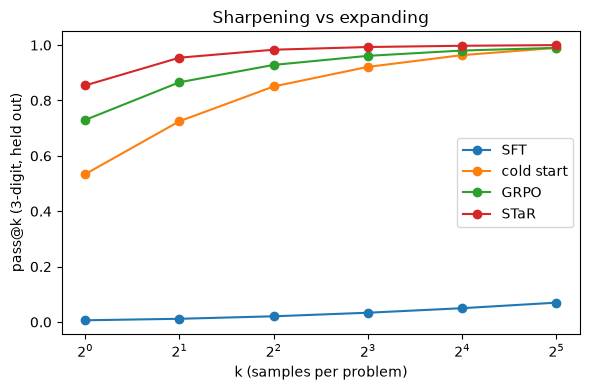

In [9]:
pk["GRPO"] = align.pass_at_k(pols["GRPO"], EVAL3[:100])
pk["STaR"] = align.pass_at_k(star, EVAL3[:100])
pkdf = pd.DataFrame(pk); display(pkdf.round(3))
fig, ax = plt.subplots(figsize=(6, 4))
for name in pkdf:
    ax.semilogx(pkdf.index, pkdf[name], "o-", label=name, base=2)
ax.set_xlabel("k (samples per problem)"); ax.set_ylabel("pass@k (3-digit, held out)"); ax.legend(); ax.set_title("Sharpening vs expanding")
fig.tight_layout(); plt.show()

The curves are the answer at our scale. GRPO and STaR lift pass@1 well above the cold start, but the curves converge
as $k$ grows: at $k = 32$ the cold-start model already solves essentially every problem that the trained models solve.
Training **sharpened** the distribution; it did not expand the set of problems the model can solve. The step that
*did* expand it was the cold-start SFT, which took pass@32 from a few percent to near 100%.

Two caveats keep this from being the whole story. Our task has no intermediate reasoning, while the R1-style
gains come with long chains of thought, where RL can change *how* the model searches. Larger studies
continue to debate whether long RL runs expand capability. Process supervision, rewarding each
correct step rather than only the final answer, is one proposed route ([Lightman et al., 2023](https://arxiv.org/abs/2305.20050), [Cobbe et al., 2021](https://arxiv.org/abs/2110.14168)).

**Where the language-model thread leaves us.** Every model so far generates **autoregressively**, one token
at a time, left to right. The second half of the series turns to a different way of generating: start from noise
and **denoise** the whole output at once. Notebook 10 brings the two threads together.

## 7. Scorecard

In [10]:
rows = []
for k, v in res.items():
    rows.append(dict(model=k + " [3-digit]", family="lm", greedy_acc=v["greedy_acc"], sampled_acc=v["sampled_acc"],
                     well_formed=v["well_formed"], kl_to_sft=v.get("kl_to_start"), acc_2d_sampled=v["acc_2d_sampled"],
                     pass_at_1=pk.get(k.split(" (")[0].replace(" (2 rounds)", ""), {}).get(1), ))
metrics.append_rows(rows, "05_rlvr")
display(metrics.load_scorecard().query("notebook == '05_rlvr'")[["model", "greedy_acc", "sampled_acc", "acc_2d_sampled", "kl_to_sft"]].round(3))

,model,greedy_acc,sampled_acc,acc_2d_sampled,kl_to_sft
18,SFT [3-digit],0.005,0.005,0.775,NaN
19,cold start (SFT + 600 demos) [3-digit],0.725,0.540,0.825,0.000
20,REINFORCE [3-digit],0.855,0.730,0.872,2.599
21,RLOO [3-digit],0.855,0.710,0.865,0.385
22,GRPO [3-digit],0.850,0.695,0.845,0.511
23,Dr. GRPO [3-digit],0.850,0.730,0.848,0.379
24,STaR (2 rounds) [3-digit],0.935,0.835,0.850,0.558


## Challenge Problem 1: Group size

GRPO's baseline is estimated from the group, so the group size $G$ matters. Keep the number of samples per
iteration fixed at 128 and compare $G = 2$ (64 prompts), $G = 8$ (16 prompts) and $G = 32$ (4 prompts) for 60
iterations. Report the held-out 3-digit sampled accuracy and the fraction of groups without signal. What trade-off
does $G$ control?

In [11]:
# Start your code here

### Challenge Problem 1 Solution

In [12]:
gs = []
for G in [2, 8, 32]:
    policy, ref = lm.load("coldstart_lm"), lm.load("coldstart_lm"); ref.requires_grad_(False)
    h = align.group_rl(policy, ref, steps=60, n_prompts=128 // G, G=G, adv="grpo", log_every=0)
    gs.append(dict(G=G, prompts_per_iter=128 // G, sampled_acc=align.evaluate(policy, EVAL3, digits=3)["sampled_acc"],
                   no_signal=h.frac_groups_no_signal.mean()))
display(pd.DataFrame(gs).round(3))
# Small G: many prompts per update, but a noisy baseline and many groups with identical rewards (no signal).
# Large G: an accurate per-prompt baseline, but few prompts per update. Report what you measure: with one seed and
# 60 iterations the accuracy differences between G values are small, while the no-signal fraction changes a lot.
# Practical systems typically use G between 8 and 64.

,G,prompts_per_iter,sampled_acc,no_signal
0,2,64,0.695,0.649
1,8,16,0.635,0.159
2,32,4,0.645,0.025


## Challenge Problem 2: What did RL cost on the old task?

Compare the 2-digit sampled accuracy (`acc_2d_sampled`) of the cold-start, GRPO and STaR models in the results table.
Did training on 3-digit problems hurt 2-digit addition? Using the KL column, explain why RLVR forgets less than the full
SFT of notebook 02.

In [13]:
# Start your code here

### Challenge Problem 2 Solution

In [14]:
display(pd.DataFrame(res).T[["acc_2d_sampled", "kl_to_start"]].round(3))
# RL with a KL penalty moves the policy very little (KL of a fraction of a nat per answer), and only on prompts it
# samples, so it leaves unrelated behaviour mostly intact. Full SFT in notebook 02 moved the model far enough to
# overwrite the 'a+b=' skill entirely. Low forgetting is one reason RL-based post-training scales well.

,acc_2d_sampled,kl_to_start
SFT,0.775,NaN
cold start (SFT + 600 demos),0.825,0.000
REINFORCE,0.872,2.599
RLOO,0.865,0.385
GRPO,0.845,0.511
Dr. GRPO,0.848,0.379
STaR (2 rounds),0.850,0.558


## Final summary

* RLVR replaces a learned reward with a **verifier**, so there is nothing to hack. The policy gradient with a group baseline (GRPO, RLOO) needs no reward model and no value network.
* RL only reinforces what the policy already does sometimes. From a model with near-zero pass@k nothing is learned, and a small **cold-start SFT** is what makes RL work, as in DeepSeek-R1.
* At our scale, RL raises pass@1 but not pass@32: it **sharpens** existing ability rather than expanding it, consistent with [Yue et al., 2025](https://arxiv.org/abs/2504.13837).
* All of this is autoregressive generation. Next, a different way to generate: diffusion.

## References

* Ronald J. Williams (1992). **Simple statistical gradient-following algorithms for connectionist reinforcement learning**. *Machine Learning*. [doi.org/10.1007/BF00992696](https://doi.org/10.1007/BF00992696)
* Eric Zelikman, Yuhuai Wu, Jesse Mu et al. (2022). **STaR: Bootstrapping Reasoning With Reasoning**. arXiv:2203.14465. [arxiv.org/abs/2203.14465](https://arxiv.org/abs/2203.14465)
* Karl Cobbe, Vineet Kosaraju, Mohammad Bavarian et al. (2021). **Training Verifiers to Solve Math Word Problems**. arXiv:2110.14168. [arxiv.org/abs/2110.14168](https://arxiv.org/abs/2110.14168)
* Mark Chen, Jerry Tworek, Heewoo Jun et al. (2021). **Evaluating Large Language Models Trained on Code**. arXiv:2107.03374. [arxiv.org/abs/2107.03374](https://arxiv.org/abs/2107.03374)
* Hunter Lightman, Vineet Kosaraju, Yura Burda et al. (2023). **Let's Verify Step by Step**. arXiv:2305.20050. [arxiv.org/abs/2305.20050](https://arxiv.org/abs/2305.20050)
* Arash Ahmadian, Chris Cremer, Matthias Gallé et al. (2024). **Back to Basics: Revisiting REINFORCE Style Optimization for Learning from Human Feedback in LLMs**. arXiv:2402.14740. [arxiv.org/abs/2402.14740](https://arxiv.org/abs/2402.14740)
* Zhihong Shao, Peiyi Wang, Qihao Zhu et al. (2024). **DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models**. arXiv:2402.03300. [arxiv.org/abs/2402.03300](https://arxiv.org/abs/2402.03300)
* Nathan Lambert, Jacob Morrison, Valentina Pyatkin et al. (2024). **Tulu 3: Pushing Frontiers in Open Language Model Post-Training**. arXiv:2411.15124. [arxiv.org/abs/2411.15124](https://arxiv.org/abs/2411.15124)
*  DeepSeek-AI, Daya Guo, Dejian Yang et al. (2025). **DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning**. arXiv:2501.12948. [arxiv.org/abs/2501.12948](https://arxiv.org/abs/2501.12948)
* Zichen Liu, Changyu Chen, Wenjun Li et al. (2025). **Understanding R1-Zero-Like Training: A Critical Perspective**. arXiv:2503.20783. [arxiv.org/abs/2503.20783](https://arxiv.org/abs/2503.20783)
* Qiying Yu, Zheng Zhang, Ruofei Zhu et al. (2025). **DAPO: An Open-Source LLM Reinforcement Learning System at Scale**. arXiv:2503.14476. [arxiv.org/abs/2503.14476](https://arxiv.org/abs/2503.14476)
* Yang Yue, Zhiqi Chen, Rui Lu et al. (2025). **Does Reinforcement Learning Really Incentivize Reasoning Capacity in LLMs Beyond the Base Model?**. arXiv:2504.13837. [arxiv.org/abs/2504.13837](https://arxiv.org/abs/2504.13837)
* Hugo Touvron, Louis Martin, Kevin Stone et al. (2023). **Llama 2: Open Foundation and Fine-Tuned Chat Models**. arXiv:2307.09288. [arxiv.org/abs/2307.09288](https://arxiv.org/abs/2307.09288)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).